In [3]:
import warnings
warnings.filterwarnings('ignore')

import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, accuracy_score, recall_score,
                             precision_score, f1_score, average_precision_score)
from xgboost import XGBClassifier

sns.set_style('whitegrid')
%matplotlib inline

In [4]:
TARGET = 'PCOS (Y/N)'
SEED = 42

IMPOSSIBLE = {
    'Pulse rate(bpm)': (40, 200),
    'BP _Systolic (mmHg)': (70, 250),
    'BP _Diastolic (mmHg)': (40, 150),
    'FSH(mIU/mL)': (0, 100),
    'LH(mIU/mL)': (0, 100),
    'Vit D3 (ng/mL)': (0, 200),
}

df = pd.read_csv('augmented_pcos.csv')
df.columns = df.columns.str.strip()

real = pd.read_csv('pcos_clean.csv')
real.columns = real.columns.str.strip()
row_key = lambda d: d[list(real.columns)].round(4).astype(str).agg('|'.join, axis=1)
is_real = pd.Series(row_key(df).isin(set(row_key(real))).values, index=df.index)

print(df.shape)
print('real rows:', int(is_real.sum()), ' synthetic rows:', int((~is_real).sum()))

(2041, 42)
real rows: 541  synthetic rows: 1500


In [5]:
df.head()

,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,1,41,64.6,162.402,24.013345,11,72,18,10.56,4,...,1,1.0,0,110,80,12,12,19.5,17.61,6.65
1,0,35,55.7,150.309,17.385120,15,79,18,9.86,4,...,1,1.0,0,120,80,10,10,14.8,13.75,8.67
2,1,24,46.3,164.695,18.951993,15,72,18,11.41,2,...,1,1.0,0,110,80,11,11,19.4,18.48,10.23
3,1,39,62.5,148.676,26.710174,15,72,18,11.56,4,...,1,1.0,0,120,80,19,13,13.7,14.23,6.92
4,0,32,52.0,163.000,19.600000,13,70,24,10.80,2,...,0,1.0,0,120,80,3,1,18.0,17.00,7.30


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2041 entries, 0 to 2040
Data columns (total 42 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PCOS (Y/N)              2041 non-null   int64  
 1   Age (yrs)               2041 non-null   int64  
 2   Weight (Kg)             2041 non-null   float64
 3   Height(Cm)              2041 non-null   float64
 4   BMI                     2041 non-null   float64
 5   Blood Group             2041 non-null   int64  
 6   Pulse rate(bpm)         2041 non-null   int64  
 7   RR (breaths/min)        2041 non-null   int64  
 8   Hb(g/dl)                2041 non-null   float64
 9   Cycle(R/I)              2041 non-null   int64  
 10  Cycle length(days)      2041 non-null   int64  
 11  Marraige Status (Yrs)   2041 non-null   float64
 12  Pregnant(Y/N)           2041 non-null   int64  
 13  No. of aborptions       2041 non-null   int64  
 14  I   beta-HCG(mIU/mL)    2041 non-null   

In [7]:
print('duplicates:', df.duplicated().sum())
print('nulls:', int(df.isnull().sum().sum()))

bad = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in IMPOSSIBLE.items()}
print('impossible values found:', bad)

derived_before = {
    'BMI': int(((df['Weight (Kg)'] / (df['Height(Cm)'] / 100) ** 2 - df['BMI']).abs() > 1).sum()),
    'Waist:Hip Ratio': int(((df['Waist(inch)'] / df['Hip(inch)'] - df['Waist:Hip Ratio']).abs() > 0.02).sum()),
    'FSH/LH': int(((df['FSH(mIU/mL)'] / df['LH(mIU/mL)'] - df['FSH/LH']).abs() > 0.1).sum()),
}
print('rows where derived column disagrees with its inputs:', derived_before)

for c, (lo, hi) in IMPOSSIBLE.items():
    df.loc[(df[c] < lo) | (df[c] > hi), c] = np.nan

df['BMI'] = df['Weight (Kg)'] / (df['Height(Cm)'] / 100) ** 2
df['Waist:Hip Ratio'] = df['Waist(inch)'] / df['Hip(inch)']
df['FSH/LH'] = (df['FSH(mIU/mL)'] / df['LH(mIU/mL)']).replace([np.inf, -np.inf], np.nan)

df.isnull().sum()[df.isnull().sum() > 0]

duplicates: 0
nulls: 0
impossible values found: {'Pulse rate(bpm)': 2, 'BP _Systolic (mmHg)': 1, 'BP _Diastolic (mmHg)': 1, 'FSH(mIU/mL)': 1, 'LH(mIU/mL)': 1, 'Vit D3 (ng/mL)': 2}
rows where derived column disagrees with its inputs: {'BMI': 1192, 'Waist:Hip Ratio': 1279, 'FSH/LH': 1453}


Pulse rate(bpm)         2
FSH(mIU/mL)             1
LH(mIU/mL)              1
FSH/LH                  2
Vit D3 (ng/mL)          2
BP _Systolic (mmHg)     1
BP _Diastolic (mmHg)    1
dtype: int64

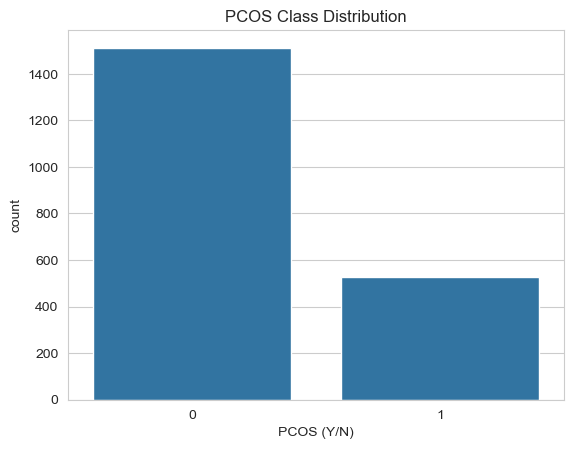

PCOS (Y/N)
0    0.740813
1    0.259187
Name: proportion, dtype: float64

In [8]:
sns.countplot(x=TARGET, data=df)
plt.title('PCOS Class Distribution')
plt.show()
df[TARGET].value_counts(normalize=True)

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),2041.0,0.259187,0.438296,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),2041.0,30.991671,5.092134,20.000000,27.000000,31.000000,35.000000,48.000000
Weight (Kg),2041.0,59.043900,9.260514,31.000000,53.000000,59.000000,64.800000,108.000000
Height(Cm),2041.0,156.328837,5.761531,137.000000,152.000000,156.066000,160.702000,180.000000
BMI,2041.0,24.146154,3.474476,12.417882,21.963253,24.179001,26.203975,40.728810
Blood Group,2041.0,14.328760,1.390867,11.000000,13.000000,15.000000,15.000000,18.000000
Pulse rate(bpm),2039.0,72.563021,1.716063,70.000000,72.000000,72.000000,72.000000,82.000000
RR (breaths/min),2041.0,18.681529,1.185077,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),2041.0,10.838466,0.629507,8.500000,10.450000,10.770000,11.100000,14.800000
Cycle(R/I),2041.0,2.359138,0.768801,2.000000,2.000000,2.000000,2.000000,5.000000


In [10]:
corr = df.corr(numeric_only=True)[TARGET].sort_values(ascending=False)
corr

PCOS (Y/N)                1.000000
Follicle No. (R)          0.679621
Skin darkening (Y/N)      0.578046
Follicle No. (L)          0.536262
hair growth(Y/N)          0.511760
Cycle(R/I)                0.481546
Weight gain(Y/N)          0.481081
Fast food (Y/N)           0.385207
AMH(ng/mL)                0.331168
Pimples(Y/N)              0.319947
Hair loss(Y/N)            0.218687
Weight (Kg)               0.213487
Hip(inch)                 0.191096
BMI                       0.189572
Waist(inch)               0.178464
Avg. F size (L) (mm)      0.130413
Avg. F size (R) (mm)      0.109810
Hb(g/dl)                  0.086454
RR (breaths/min)          0.084438
Height(Cm)                0.078372
Reg.Exercise(Y/N)         0.076057
RBS(mg/dl)                0.074044
BP _Systolic (mmHg)       0.073747
LH(mIU/mL)                0.072972
Pulse rate(bpm)           0.072496
Endometrium (mm)          0.068958
Blood Group               0.064398
FSH/LH                    0.028415
TSH (mIU/L)         

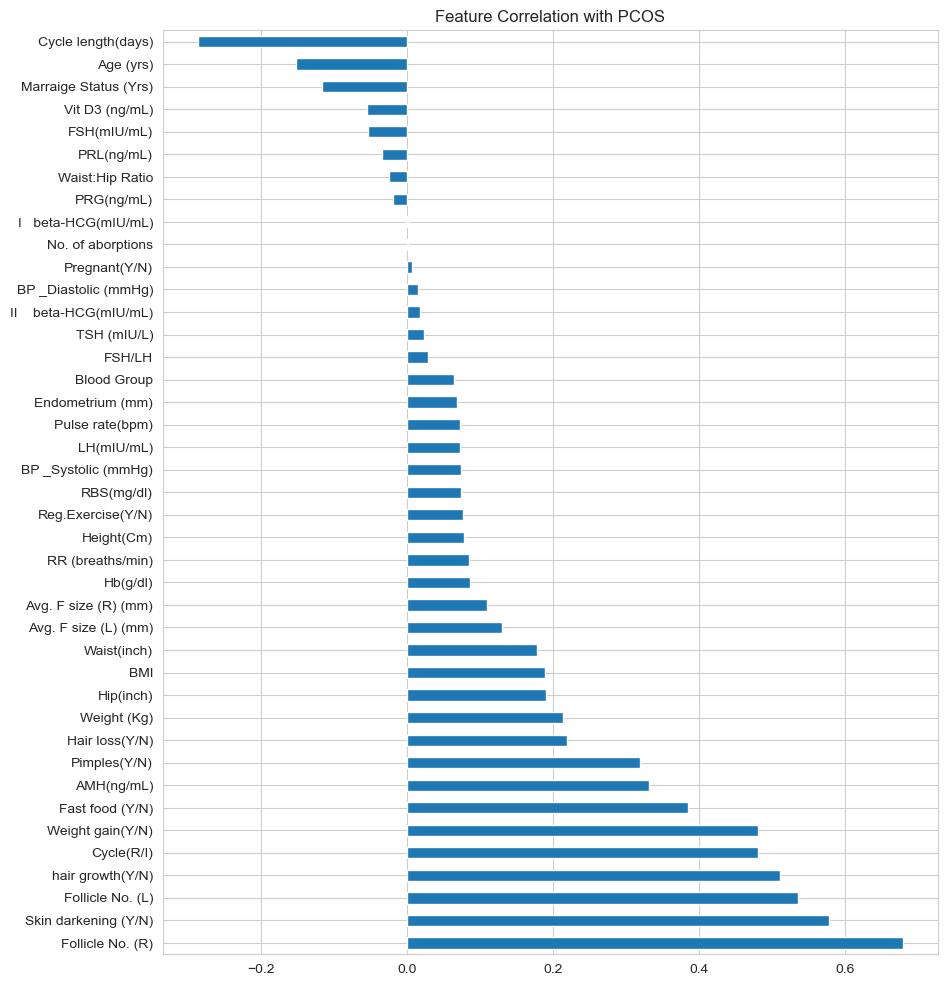

In [11]:
plt.figure(figsize=(10, 12))
corr.drop(TARGET).plot(kind='barh')
plt.title('Feature Correlation with PCOS')
plt.show()

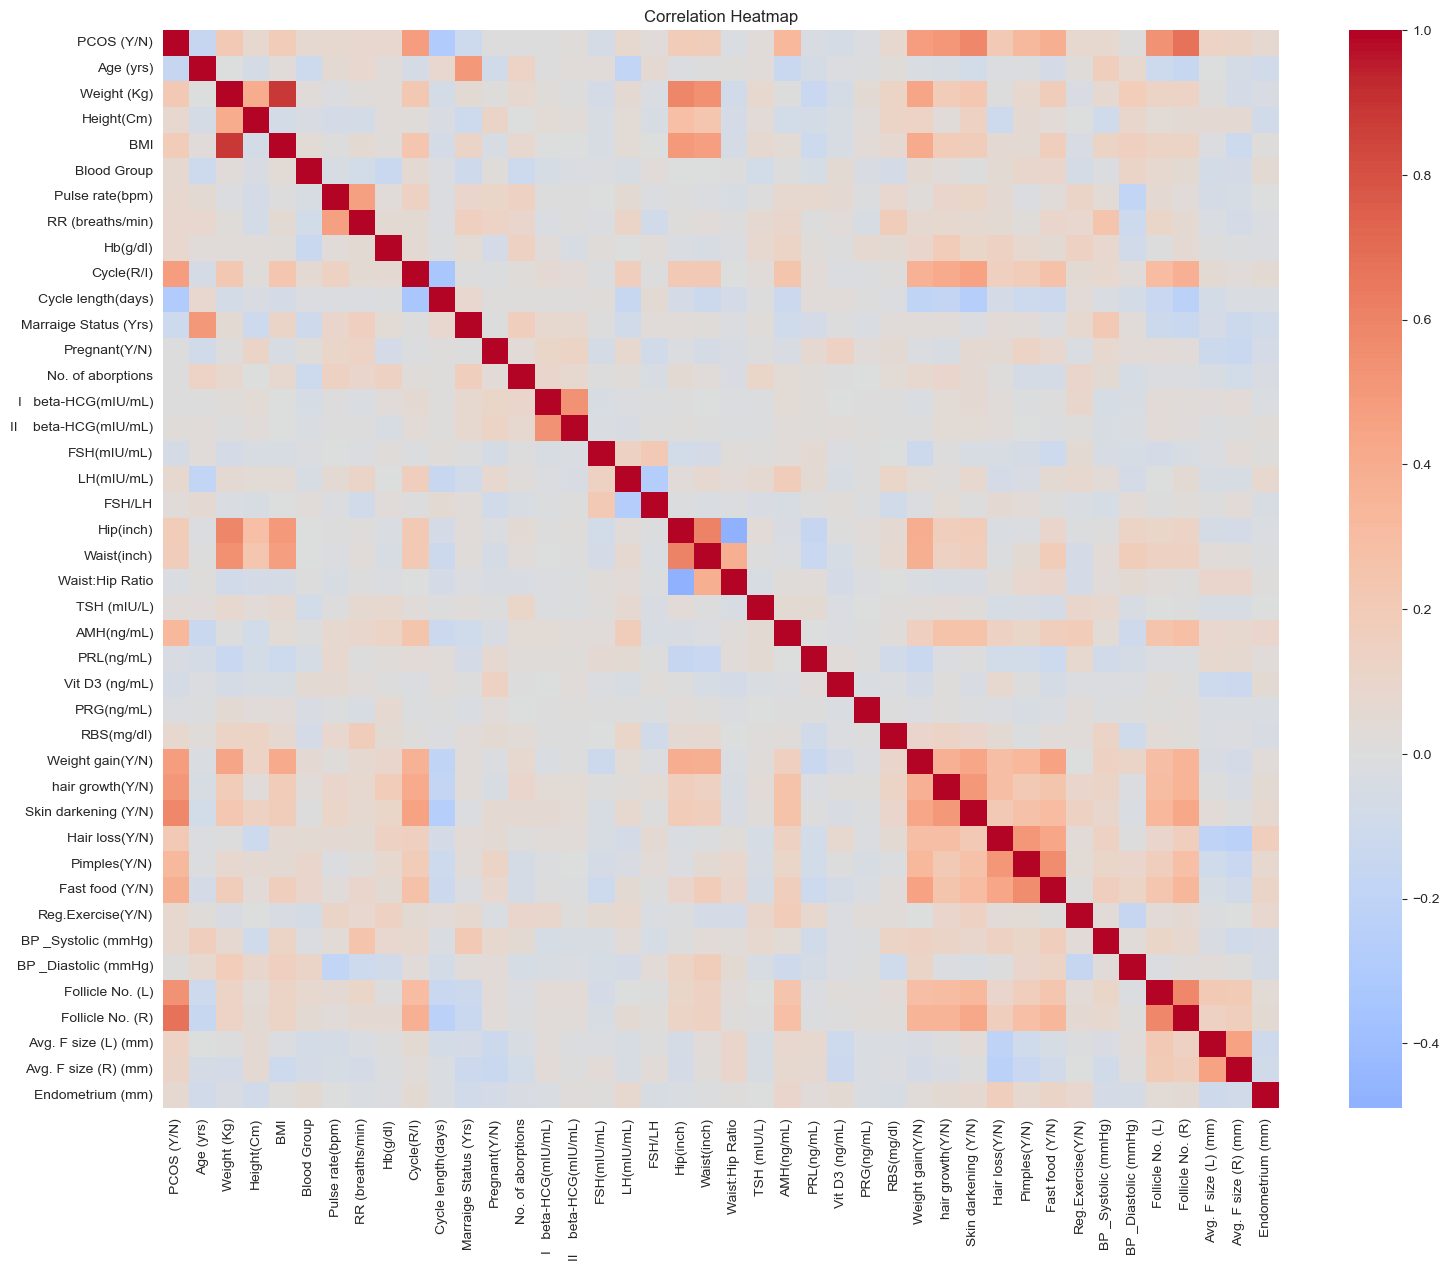

In [12]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

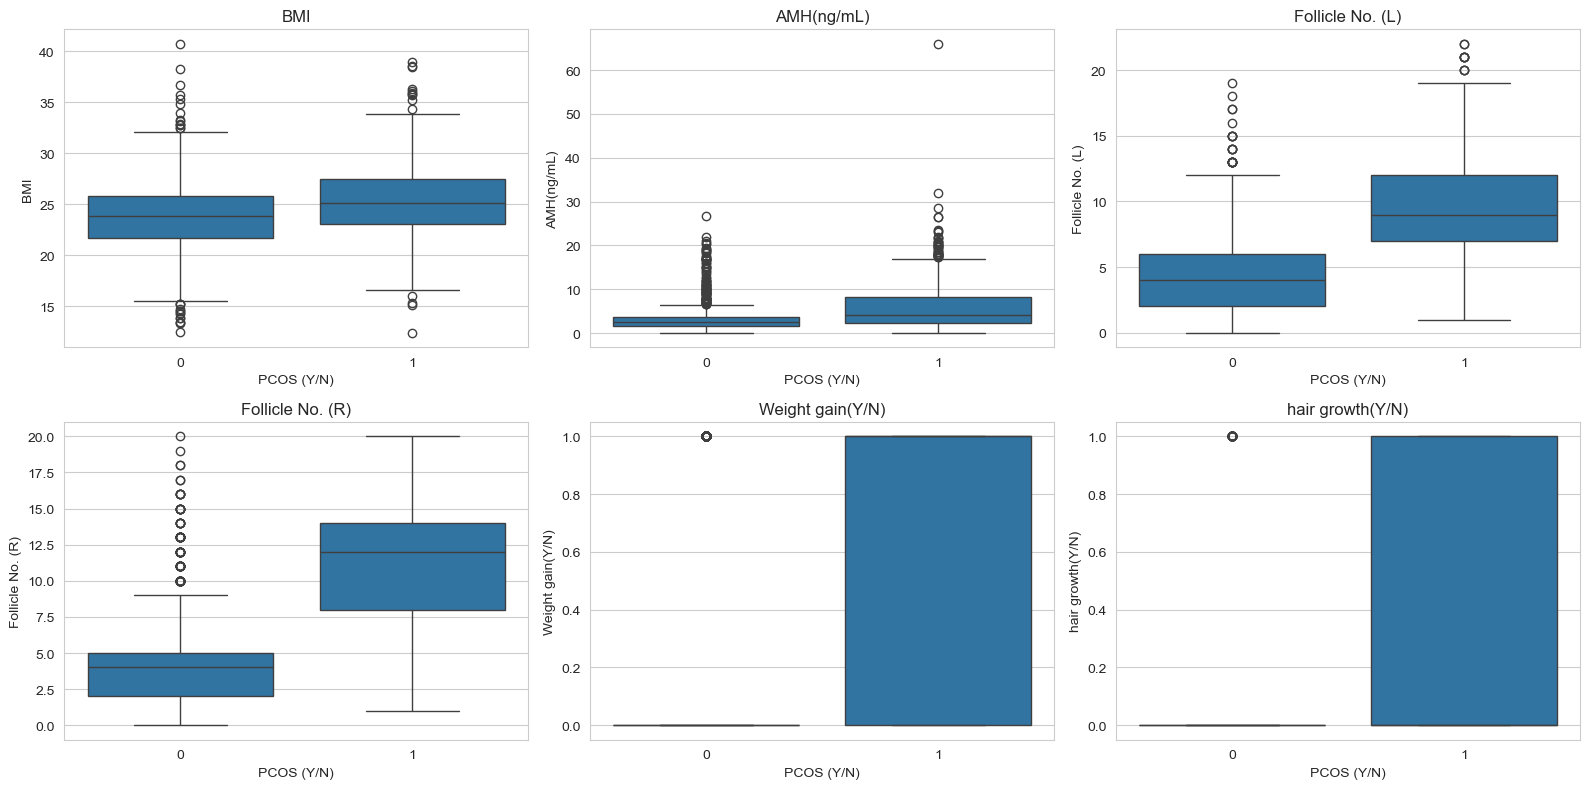

In [13]:
key_features = ['BMI', 'AMH(ng/mL)', 'Follicle No. (L)', 'Follicle No. (R)', 'Weight gain(Y/N)', 'hair growth(Y/N)']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.flatten(), key_features):
    sns.boxplot(x=TARGET, y=feat, data=df, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

In [14]:
X = df.drop(columns=[TARGET])
y = df[TARGET]
cols = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

print('train', X_train.shape, ' test', X_test.shape)
print('positive rate  train %.3f  test %.3f' % (y_train.mean(), y_test.mean()))
print('real rows in test:', int(is_real.loc[X_test.index].sum()))

train (1632, 41)  test (409, 41)
positive rate  train 0.259  test 0.259
real rows in test: 106


In [15]:
pos_w = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5),
    'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                        class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric='logloss',
                        random_state=SEED, n_jobs=-1),
    'SVM': SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=SEED),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                        max_depth=3, subsample=0.8, random_state=SEED),
}

needs_scaling = ['Logistic Regression', 'SVM']
pipes = {}
for name, m in models.items():
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if name in needs_scaling:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', m))
    pipes[name] = Pipeline(steps)
list(pipes)

['Logistic Regression', 'Random Forest', 'XGBoost', 'SVM', 'Gradient Boosting']

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}

rows = []
for name, p in pipes.items():
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name, **{k: r['test_' + k].mean() for k in scoring},
                 'auc_std': r['test_auc'].std()})

cv_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False)
best_name = cv_table.index[0]
print('Best model by CV AUC:', best_name)
cv_table.round(3)

Best model by CV AUC: Random Forest


,auc,recall,precision,f1,accuracy,auc_std
model,,,,,,
Random Forest,0.966,0.832,0.864,0.846,0.922,0.006
Gradient Boosting,0.966,0.837,0.857,0.846,0.921,0.006
XGBoost,0.965,0.880,0.808,0.841,0.914,0.007
SVM,0.960,0.856,0.804,0.828,0.908,0.006
Logistic Regression,0.960,0.901,0.783,0.837,0.909,0.008


In [17]:
fitted, probs, rows = {}, {}, []
for name, p in pipes.items():
    p.fit(X_train, y_train)
    fitted[name] = p
    pr = p.predict_proba(X_test)[:, 1]
    pred = (pr >= 0.5).astype(int)
    probs[name] = pr
    rows.append({'model': name,
                 'auc': roc_auc_score(y_test, pr),
                 'pr_auc': average_precision_score(y_test, pr),
                 'accuracy': accuracy_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'f1': f1_score(y_test, pred)})

test_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False)
test_table.round(3)

,auc,pr_auc,accuracy,recall,precision,f1
model,,,,,,
XGBoost,0.975,0.944,0.932,0.896,0.848,0.872
Gradient Boosting,0.975,0.941,0.939,0.868,0.893,0.880
Logistic Regression,0.974,0.942,0.914,0.896,0.798,0.844
Random Forest,0.973,0.945,0.939,0.858,0.901,0.879
SVM,0.969,0.942,0.922,0.840,0.856,0.848


In [18]:
best = fitted[best_name]
print('Selected by CV:', best_name)
print(classification_report(y_test, (probs[best_name] >= 0.5).astype(int), target_names=['No PCOS', 'PCOS']))

rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        aucs.append(roc_auc_score(yt[idx], probs[best_name][idx]))
print('Test AUC 95%% CI for %s: %.3f - %.3f' % (best_name, np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)))

Selected by CV: Random Forest
              precision    recall  f1-score   support

     No PCOS       0.95      0.97      0.96       303
        PCOS       0.90      0.86      0.88       106

    accuracy                           0.94       409
   macro avg       0.93      0.91      0.92       409
weighted avg       0.94      0.94      0.94       409

Test AUC 95% CI for Random Forest: 0.955 - 0.986


In [19]:
mask = is_real.loc[X_test.index].to_numpy()
rows = []
for name, pr in probs.items():
    pred = (pr[mask] >= 0.5).astype(int)
    rows.append({'model': name,
                 'n_rows': int(mask.sum()),
                 'auc': roc_auc_score(y_test[mask], pr[mask]),
                 'pr_auc': average_precision_score(y_test[mask], pr[mask]),
                 'recall': recall_score(y_test[mask], pred),
                 'precision': precision_score(y_test[mask], pred),
                 'f1': f1_score(y_test[mask], pred)})
pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False).round(3)

,n_rows,auc,pr_auc,recall,precision,f1
model,,,,,,
Gradient Boosting,106,0.963,0.904,0.889,0.800,0.842
Random Forest,106,0.956,0.907,0.852,0.852,0.852
XGBoost,106,0.953,0.902,0.889,0.750,0.814
Logistic Regression,106,0.947,0.884,0.889,0.686,0.774
SVM,106,0.933,0.876,0.778,0.750,0.764


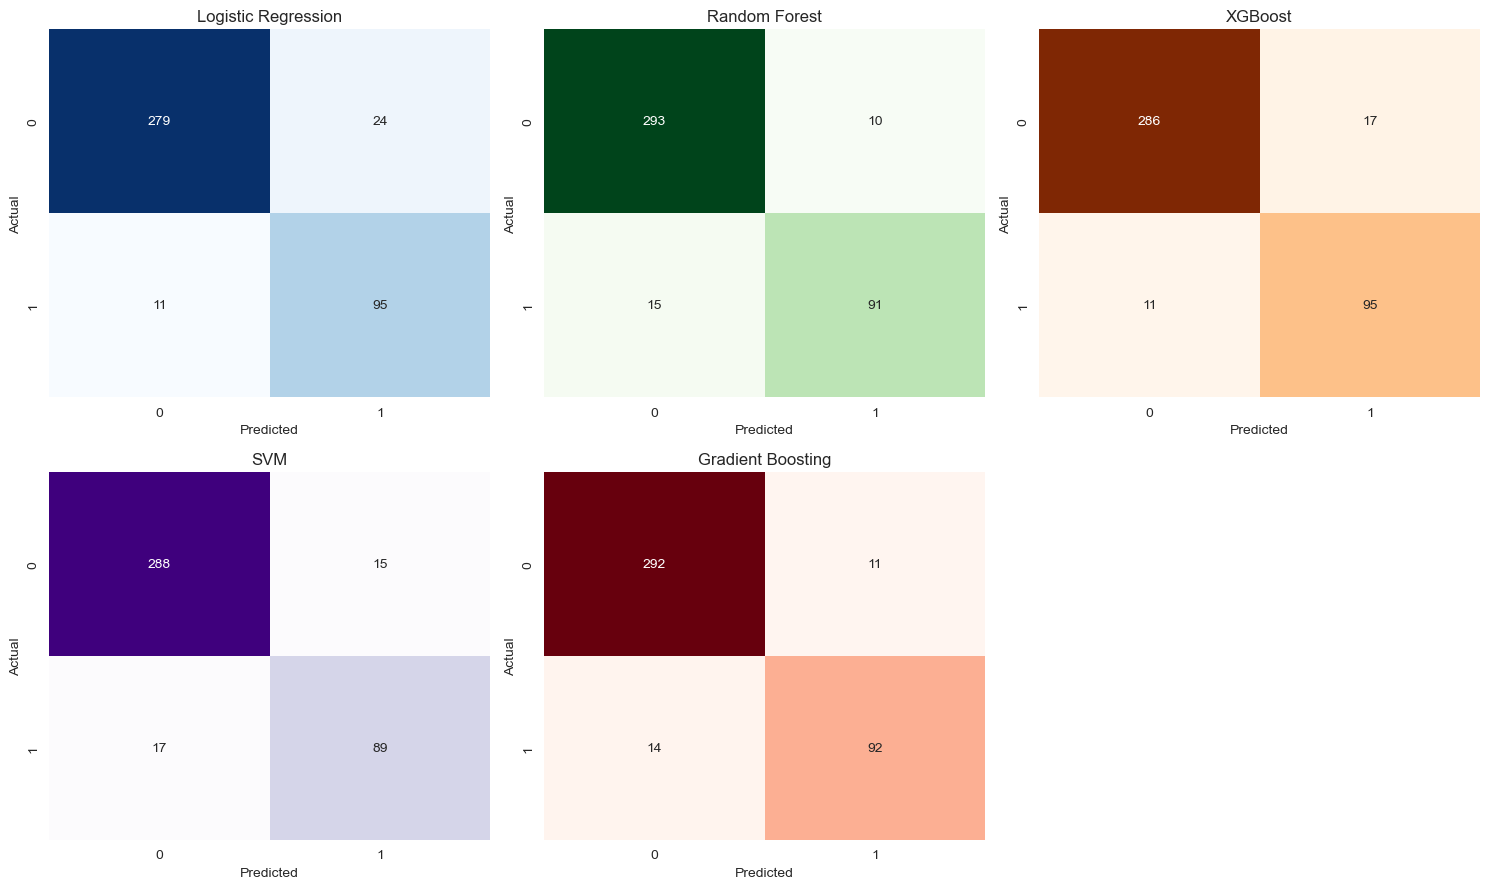

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
cmaps = ['Blues', 'Greens', 'Oranges', 'Purples', 'Reds']
for ax, (name, pr), cm in zip(axes.flatten(), probs.items(), cmaps):
    sns.heatmap(confusion_matrix(y_test, (pr >= 0.5).astype(int)), annot=True, fmt='d', cmap=cm, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
axes[1, 2].axis('off')
plt.tight_layout(); plt.show()

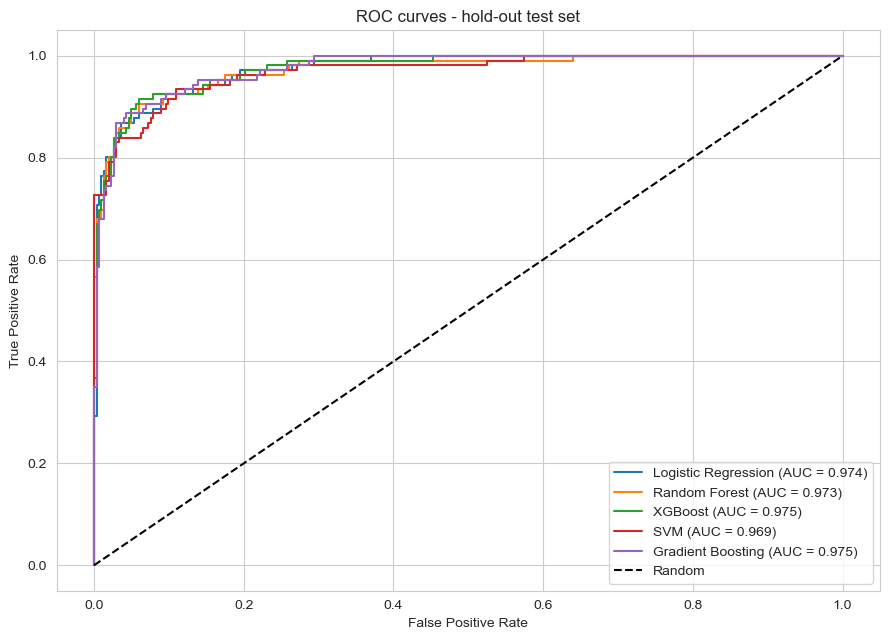

In [21]:
plt.figure(figsize=(9, 6.5))
for name, pr in probs.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, pr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves - hold-out test set'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

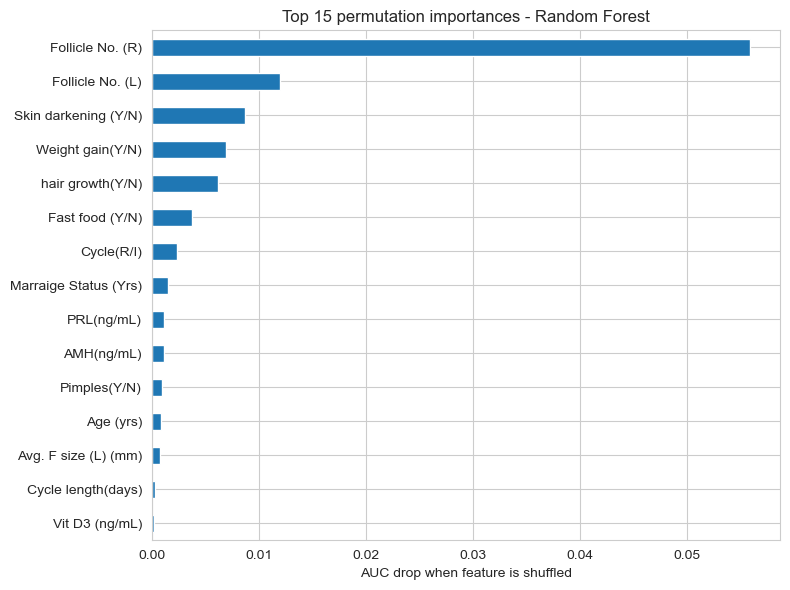

In [22]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc',
                              n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind='barh', figsize=(8, 6))
plt.title(f'Top 15 permutation importances - {best_name}')
plt.xlabel('AUC drop when feature is shuffled'); plt.tight_layout(); plt.show()

In [23]:
feature_medians = {c: float(X_train[c].median()) for c in cols}

with open('feature_medians.json', 'w') as f:
    json.dump(feature_medians, f, indent=2)

with open('feature_schema.pkl', 'wb') as f:
    pickle.dump(cols, f)

final_rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                  class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
final_rf.fit(X_train.fillna(feature_medians), y_train)

with open('rf_pcos_model.pkl', 'wb') as f:
    pickle.dump(final_rf, f)

with open('feature_schema.pkl', 'rb') as f:
    schema_check = pickle.load(f)
with open('feature_medians.json') as f:
    medians_check = json.load(f)
with open('rf_pcos_model.pkl', 'rb') as f:
    model_check = pickle.load(f)

assert schema_check == cols
assert list(medians_check) == cols
assert list(model_check.feature_names_in_) == cols

reloaded_prob = model_check.predict_proba(X_test[schema_check].fillna(medians_check))[:, 1]
print('saved: feature_medians.json, feature_schema.pkl, rf_pcos_model.pkl')
print('features:', len(schema_check))
print('reloaded model test AUC: %.3f' % roc_auc_score(y_test, reloaded_prob))

saved: feature_medians.json, feature_schema.pkl, rf_pcos_model.pkl
features: 41
reloaded model test AUC: 0.973
